# Identifying Bias in AI
## Exploratory Data Analysis of Jigsaw Toxicity Dataset

### Project Objective
The objective of this project is to explore potential bias in AI-based toxicity classification by analyzing toxicity scores, identity-related attributes, and comment patterns.

### Dataset
Jigsaw Unintended Bias in Toxicity Classification

### Tools & Libraries
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Plotly

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load dataset

df = pd.read_csv("bias_dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
# Check dataset dimensions

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 90902
Number of Columns: 45


In [4]:
df.head()

,id,target,comment_text,severe_toxicity,obscene,identity_attack,insult,threat,asian,atheist,...,article_id,rating,funny,wow,sad,likes,disagree,sexual_explicit,identity_annotator_count,toxicity_annotator_count
0,59856,0.893617,haha you guys are a bunch of losers.,0.021277,0.000000,0.021277,0.872340,0.0000,0.0,0.0,...,2006,rejected,0,0,0,1,0,0.000000,4,47
1,239607,0.912500,Yet call out all Muslims for the acts of a few...,0.050000,0.237500,0.612500,0.887500,0.1125,0.0,0.0,...,26670,approved,0,0,0,1,0,0.000000,4,80
2,239612,0.830769,This bitch is nuts. Who would read a book by a...,0.107692,0.661538,0.338462,0.830769,0.0000,0.0,0.0,...,26674,rejected,0,0,0,0,0,0.061538,4,65
3,240311,0.968750,You're an idiot.,0.031250,0.062500,0.000000,0.968750,0.0000,NaN,NaN,...,32846,rejected,0,0,0,0,0,0.000000,0,32
4,240329,0.900000,Who cares!? Stark trek and Star Wars fans are ...,0.100000,0.200000,0.000000,0.900000,0.0000,NaN,NaN,...,32846,rejected,0,0,0,0,0,0.300000,0,10


In [5]:
# Dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 90902 entries, 0 to 90901
Data columns (total 45 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   id                                   90902 non-null  int64  
 1   target                               90902 non-null  float64
 2   comment_text                         90902 non-null  str    
 3   severe_toxicity                      90902 non-null  float64
 4   obscene                              90902 non-null  float64
 5   identity_attack                      90902 non-null  float64
 6   insult                               90902 non-null  float64
 7   threat                               90902 non-null  float64
 8   asian                                21687 non-null  float64
 9   atheist                              21687 non-null  float64
 10  bisexual                             21687 non-null  float64
 11  black                                21

In [6]:
# Statistical summary of numerical columns

df.describe()

,id,target,severe_toxicity,obscene,identity_attack,insult,threat,asian,atheist,bisexual,...,parent_id,article_id,funny,wow,sad,likes,disagree,sexual_explicit,identity_annotator_count,toxicity_annotator_count
count,9.090200e+04,90902.000000,90902.000000,90902.000000,90902.000000,90902.000000,90902.000000,21687.00000,21687.000000,21687.000000,...,4.983000e+04,90902.000000,90902.000000,90902.000000,90902.000000,90902.000000,90902.000000,90902.000000,90902.000000,90902.000000
mean,3.741905e+06,0.430254,0.020783,0.091598,0.054786,0.381360,0.025486,0.01059,0.003179,0.001616,...,3.683063e+06,281545.713736,0.258938,0.043365,0.106741,2.334360,0.559207,0.023667,1.535489,36.632560
std,2.450000e+06,0.406086,0.043101,0.182411,0.147375,0.386545,0.109004,0.08227,0.051270,0.024006,...,2.458295e+06,104028.940513,0.994396,0.240804,0.453165,4.587831,1.735908,0.106960,18.199186,147.288485
min,5.985600e+04,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,...,2.210600e+05,2006.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
25%,7.921310e+05,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,...,7.825040e+05,159937.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000
50%,5.232225e+06,0.500120,0.000000,0.000000,0.000000,0.200000,0.000000,0.00000,0.000000,0.000000,...,5.208236e+06,332720.500000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,6.000000
75%,5.785647e+06,0.810345,0.026316,0.116667,0.021739,0.785714,0.000000,0.00000,0.000000,0.000000,...,5.769276e+06,367055.000000,0.000000,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,58.000000
max,6.333872e+06,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,...,6.333696e+06,399523.000000,58.000000,8.000000,16.000000,224.000000,96.000000,1.000000,1838.000000,4936.000000


In [7]:
# Summary of categorical columns

df.describe(include="object")

C:\Users\Yousuf Traders\AppData\Local\Temp\ipykernel_14812\2647003901.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,comment_text,created_date,rating
count,90902,90902,90902
unique,90137,90885,2
top,You're an idiot.,2016-01-15 12:34:59.545931+00,approved
freq,19,4,74917


### Dataset Overview

The dataset contains 90,902 rows and 45 columns. It includes numerical, categorical, and text-based information related to online comments and toxicity classification.

### Data Types

Most columns contain numerical values, while comment_text, created_date, and rating are stored as object data types. The created_date column will be converted into datetime format during data cleaning.

## Column Guide

| Column | Meaning |
|---|---|
| id | Unique comment identifier |
| target | Overall toxicity score |
| comment_text | Actual text of the comment |
| severe_toxicity | Severe toxicity score |
| obscene | Obscene language score |
| identity_attack | Identity attack score |
| insult | Insult score |
| threat | Threat score |
| asian | Asian identity annotation |
| atheist | Atheist identity annotation |
| bisexual | Bisexual identity annotation |
| black | Black identity annotation |
| buddhist | Buddhist identity annotation |
| christian | Christian identity annotation |
| female | Female identity annotation |
| heterosexual | Heterosexual identity annotation |
| hindu | Hindu identity annotation |
| homosexual_gay_or_lesbian | Sexual orientation annotation |
| intellectual_or_learning_disability | Learning disability annotation |
| jewish | Jewish identity annotation |
| latino | Latino identity annotation |
| male | Male identity annotation |
| muslim | Muslim identity annotation |
| other_disability | Other disability annotation |
| other_gender | Other gender annotation |
| other_race_or_ethnicity | Other race or ethnicity annotation |
| other_religion | Other religion annotation |
| other_sexual_orientation | Other sexual orientation annotation |
| physical_disability | Physical disability annotation |
| psychiatric_or_mental_illness | Mental illness annotation |
| transgender | Transgender identity annotation |
| white | White identity annotation |
| created_date | Comment creation date and time |
| publication_id | Publication identifier |
| parent_id | Parent comment identifier |
| article_id | Article identifier |
| rating | Comment moderation status |
| funny | Number of funny reactions |
| wow | Number of wow reactions |
| sad | Number of sad reactions |
| likes | Number of likes |
| disagree | Number of disagree reactions |
| sexual_explicit | Sexually explicit content score |
| identity_annotator_count | Number of identity annotators |
| toxicity_annotator_count | Number of toxicity annotators |

### Dataset Understanding

This dataset contains online comments with toxicity scores, identity-related annotations, moderation ratings, and user reactions.

Each row represents one online comment. The dataset helps us explore potential differences in toxicity classification across identity-related categories.

## Research Questions

1. What is the distribution of overall toxicity scores?
2. What percentage of comments are classified as toxic?
3. Which type of toxic content is most common?
4. How frequently are different identity groups mentioned?
5. Do comments mentioning different identities have different average toxicity scores?
6. Is identity attack score related to overall toxicity?
7. How do approved and rejected comments differ in toxicity scores?
8. Is there a relationship between comment likes and toxicity scores?

## Step 3: Data Cleaning

### 3.1 Missing Values Analysis

In this section, we will identify and visualize missing values in the dataset before deciding how to handle them.

In [ ]:
# Calculate missing values

missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

print("Total Missing Values:", df.isnull().sum().sum())

print("\nColumns with Missing Values:")
print(missing_values.sort_values(ascending=False))

In [ ]:
# Calculate missing percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage = missing_percentage[missing_percentage > 0]

missing_percentage.sort_values(ascending=False)

In [25]:
# Visualize missing values

plt.figure(figsize=(14, 8))

missing_values.sort_values().plot(
    kind="barh",
    color="mediumpurple"
)

plt.title("Missing Values by Column")
plt.xlabel("Number of Missing Values")
plt.ylabel("Columns")

plt.tight_layout()
plt.show()

NameError: name 'missing_values' is not defined

<Figure size 1400x800 with 0 Axes>

### Missing Values Interpretation

The dataset contains approximately 41.61% missing cells. Most missing values occur in identity-related annotation columns, with 69,215 missing values in each. The parent_id column also contains 41,072 missing values.

These missing values require careful handling because they may represent unavailable annotations rather than zero values.

### 3.2 Duplicate Records

In this section, we will identify repeated rows in the dataset and remove them if any are found.

In [8]:
# Count duplicate rows

duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)

Total Duplicate Rows: 0


In [10]:
# Remove duplicate rows

df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

Dataset Shape After Removing Duplicates: (90902, 45)


### Duplicate Records Interpretation

The dataset contained zero duplicate rows. Therefore, no records were removed during duplicate cleaning. All 90,902 rows were retained.

### 3.3 Data Types Correction

We will inspect the existing data types and convert the date column into the appropriate datetime format.

In [11]:
# Check existing data types

df.dtypes

id                                       int64
target                                 float64
comment_text                               str
severe_toxicity                        float64
obscene                                float64
identity_attack                        float64
insult                                 float64
threat                                 float64
asian                                  float64
atheist                                float64
bisexual                               float64
black                                  float64
buddhist                               float64
christian                              float64
female                                 float64
heterosexual                           float64
hindu                                  float64
homosexual_gay_or_lesbian              float64
intellectual_or_learning_disability    float64
jewish                                 float64
latino                                 float64
male         

In [12]:
# Convert created_date into datetime

df["created_date"] = pd.to_datetime(df["created_date"], errors="coerce")

print("Updated Data Type:", df["created_date"].dtype)

Updated Data Type: datetime64[us, UTC]


In [13]:
# Verify data types after conversion

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 90902 entries, 0 to 90901
Data columns (total 45 columns):
 #   Column                               Non-Null Count  Dtype              
---  ------                               --------------  -----              
 0   id                                   90902 non-null  int64              
 1   target                               90902 non-null  float64            
 2   comment_text                         90902 non-null  str                
 3   severe_toxicity                      90902 non-null  float64            
 4   obscene                              90902 non-null  float64            
 5   identity_attack                      90902 non-null  float64            
 6   insult                               90902 non-null  float64            
 7   threat                               90902 non-null  float64            
 8   asian                                21687 non-null  float64            
 9   atheist                              21

### Data Types Interpretation

The created_date column was originally stored as an object data type. It was converted into datetime format to support time-based analysis and visualization.

### 3.4 Outlier Detection

Outliers are unusually high or low values that differ from most observations. We will identify them using boxplots and the IQR method.

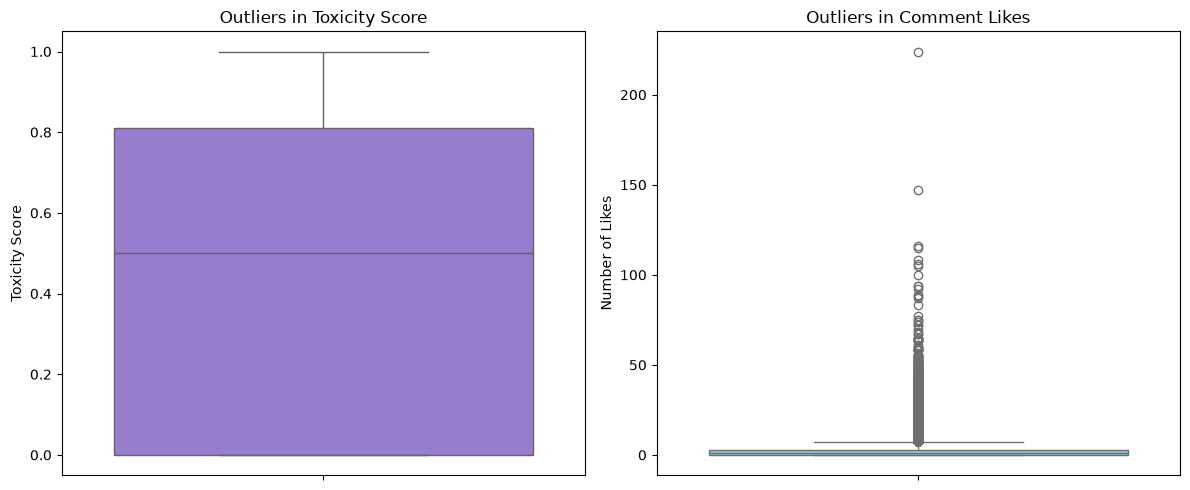

In [14]:
# Boxplots for outlier detection

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df["target"], color="mediumpurple")
plt.title("Outliers in Toxicity Score")
plt.ylabel("Toxicity Score")

plt.subplot(1, 2, 2)
sns.boxplot(y=df["likes"], color="skyblue")
plt.title("Outliers in Comment Likes")
plt.ylabel("Number of Likes")

plt.tight_layout()
plt.show()

In [15]:
# IQR method for detecting outliers

columns = ["target", "likes"]

for column in columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print("\nColumn:", column)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Total Outliers:", len(outliers))


Column: target
Q1: 0.0
Q3: 0.810344828
IQR: 0.810344828
Lower Limit: -1.215517242
Upper Limit: 2.02586207
Total Outliers: 0

Column: likes
Q1: 0.0
Q3: 3.0
IQR: 3.0
Lower Limit: -4.5
Upper Limit: 7.5
Total Outliers: 7135


### Outlier Analysis and Decision

The IQR method identified no outliers in the target column and 7,135 outliers in the likes column.

The likes outliers were retained because unusually high engagement values may represent genuine user activity. Removing them could result in loss of meaningful information.

## 5. Univariate Analysis

Univariate analysis helps us understand the distribution of individual variables in the dataset. We will use histograms and count plots to identify patterns and frequencies.

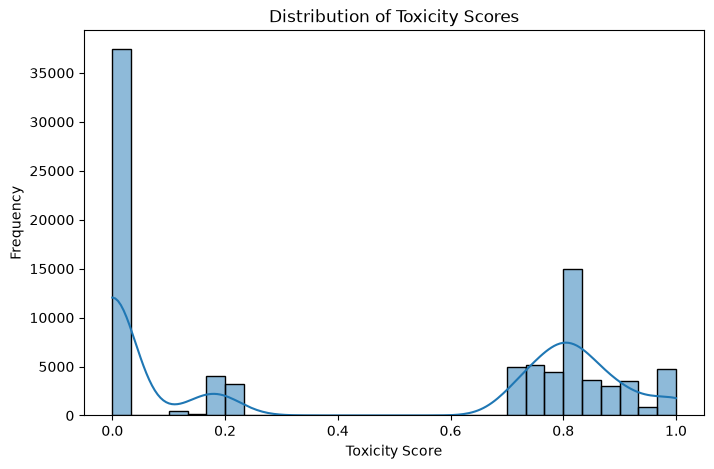

In [16]:
plt.figure(figsize=(8, 5))

sns.histplot(df["target"], bins=30, kde=True)

plt.title("Distribution of Toxicity Scores")
plt.xlabel("Toxicity Score")
plt.ylabel("Frequency")

plt.show()

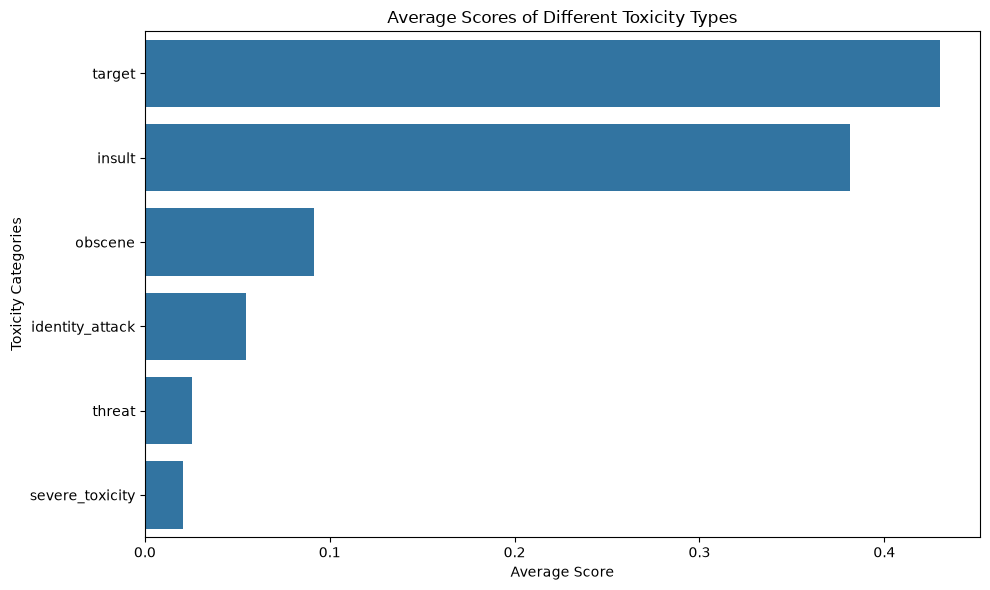

In [17]:
# Distribution of different toxicity types

toxicity_columns = [
    "target",
    "severe_toxicity",
    "obscene",
    "identity_attack",
    "insult",
    "threat"
]

toxicity_means = df[toxicity_columns].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=toxicity_means.values,
    y=toxicity_means.index
)

plt.title("Average Scores of Different Toxicity Types")
plt.xlabel("Average Score")
plt.ylabel("Toxicity Categories")

plt.tight_layout()
plt.show()

### Toxicity Categories Analysis

This visualization compares the average scores of different toxicity categories. It helps identify which types of harmful content have higher average scores in the dataset.

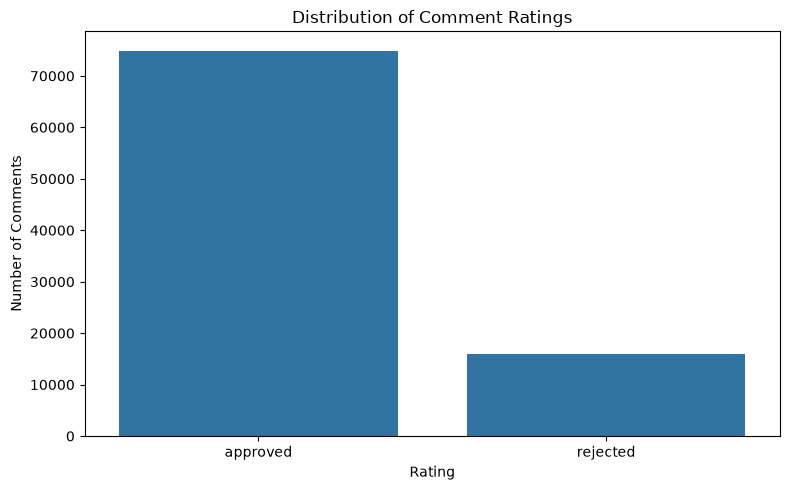

In [18]:
# Distribution of comment ratings

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="rating",
    order=df["rating"].value_counts().index
)

plt.title("Distribution of Comment Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Comments")

plt.tight_layout()
plt.show()

### Rating Distribution Analysis

This chart shows the frequency of each moderation rating in the dataset. It helps us understand how comments are distributed across moderation categories.

### 5.2 Identity-Related Analysis

This section explores identity-related annotations in online comments to understand how toxicity scores vary across different identity categories.

In [19]:
# Select identity-related columns

identity_columns = [
    "male",
    "female",
    "transgender",
    "muslim",
    "christian",
    "jewish",
    "hindu",
    "black",
    "white",
    "asian"
]

print("Selected Identity Columns:")
print(identity_columns)

Selected Identity Columns:
['male', 'female', 'transgender', 'muslim', 'christian', 'jewish', 'hindu', 'black', 'white', 'asian']


In [20]:
# Count identity-related annotations

identity_counts = (df[identity_columns] > 0).sum()

identity_counts = identity_counts.sort_values(ascending=False)

print(identity_counts)

male           4601
female         4063
christian      2436
white          2025
muslim         1680
black          1450
jewish          522
asian           521
transgender     314
hindu            72
dtype: int64


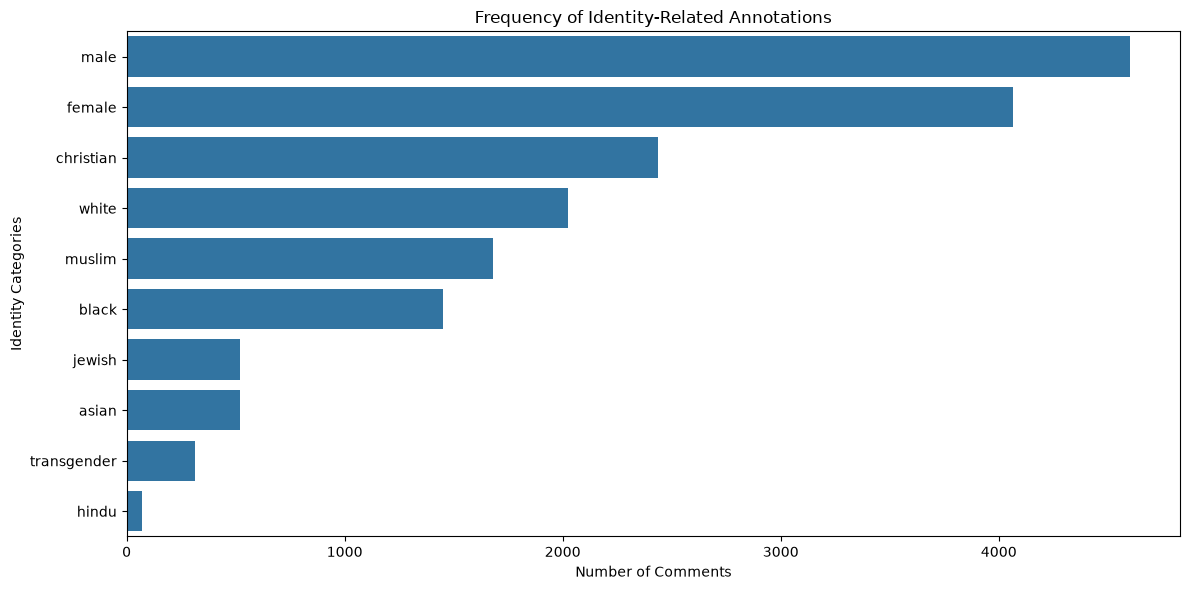

In [21]:
# Visualize identity-related annotations

plt.figure(figsize=(12, 6))

sns.barplot(
    x=identity_counts.values,
    y=identity_counts.index
)

plt.title("Frequency of Identity-Related Annotations")
plt.xlabel("Number of Comments")
plt.ylabel("Identity Categories")

plt.tight_layout()
plt.show()

### Identity Annotation Analysis

This chart compares the frequency of non-zero identity-related annotations across selected categories. It helps identify which identity categories are more frequently represented in the dataset.

These annotations do not establish the actual identity of comment authors.

### 5.3 Comparing Toxicity Scores Across Identity Categories

We will compare average toxicity scores for comments with non-zero identity annotations across selected identity categories.

In [22]:
# Calculate average toxicity for identity-related comments

identity_toxicity = {}

for column in identity_columns:

    selected_comments = df[df[column] > 0]

    average_toxicity = selected_comments["target"].mean()

    identity_toxicity[column] = average_toxicity

identity_toxicity = pd.Series(identity_toxicity)

print(identity_toxicity.sort_values(ascending=False))

black          0.671153
white          0.656605
muslim         0.611415
transgender    0.566951
male           0.538628
jewish         0.535526
female         0.528640
hindu          0.503373
asian          0.461059
christian      0.346854
dtype: float64


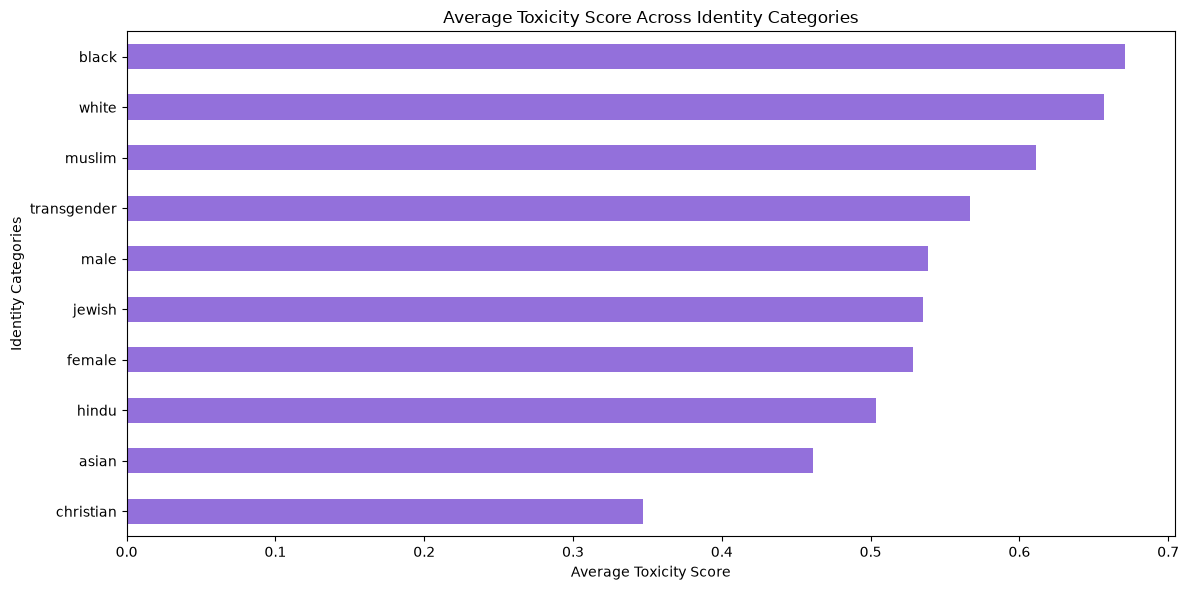

In [23]:
# Plot average toxicity by identity

plt.figure(figsize=(12, 6))

identity_toxicity.sort_values().plot(
    kind="barh",
    color="mediumpurple"
)

plt.title("Average Toxicity Score Across Identity Categories")
plt.xlabel("Average Toxicity Score")
plt.ylabel("Identity Categories")

plt.tight_layout()
plt.show()

In [24]:
# Compare average toxicity and sample size

identity_comparison = pd.DataFrame({
    "Comment_Count": (df[identity_columns] > 0).sum(),
    "Average_Toxicity": identity_toxicity
})

identity_comparison = identity_comparison.sort_values(
    by="Average_Toxicity",
    ascending=False
)

identity_comparison

,Comment_Count,Average_Toxicity
black,1450,0.671153
white,2025,0.656605
muslim,1680,0.611415
transgender,314,0.566951
male,4601,0.538628
jewish,522,0.535526
female,4063,0.528640
hindu,72,0.503373
asian,521,0.461059
christian,2436,0.346854


### Identity-Based Toxicity Comparison

The analysis compares average toxicity scores across comments with different identity-related annotations.

Differences in average scores may indicate patterns worth investigating. However, these differences do not independently prove AI bias because they may also reflect comment context, language, or annotation practices.

## 6. Bivariate Analysis

Bivariate analysis examines the relationship between two variables. We will use scatter plots and correlation heatmaps to identify possible relationships in the dataset.

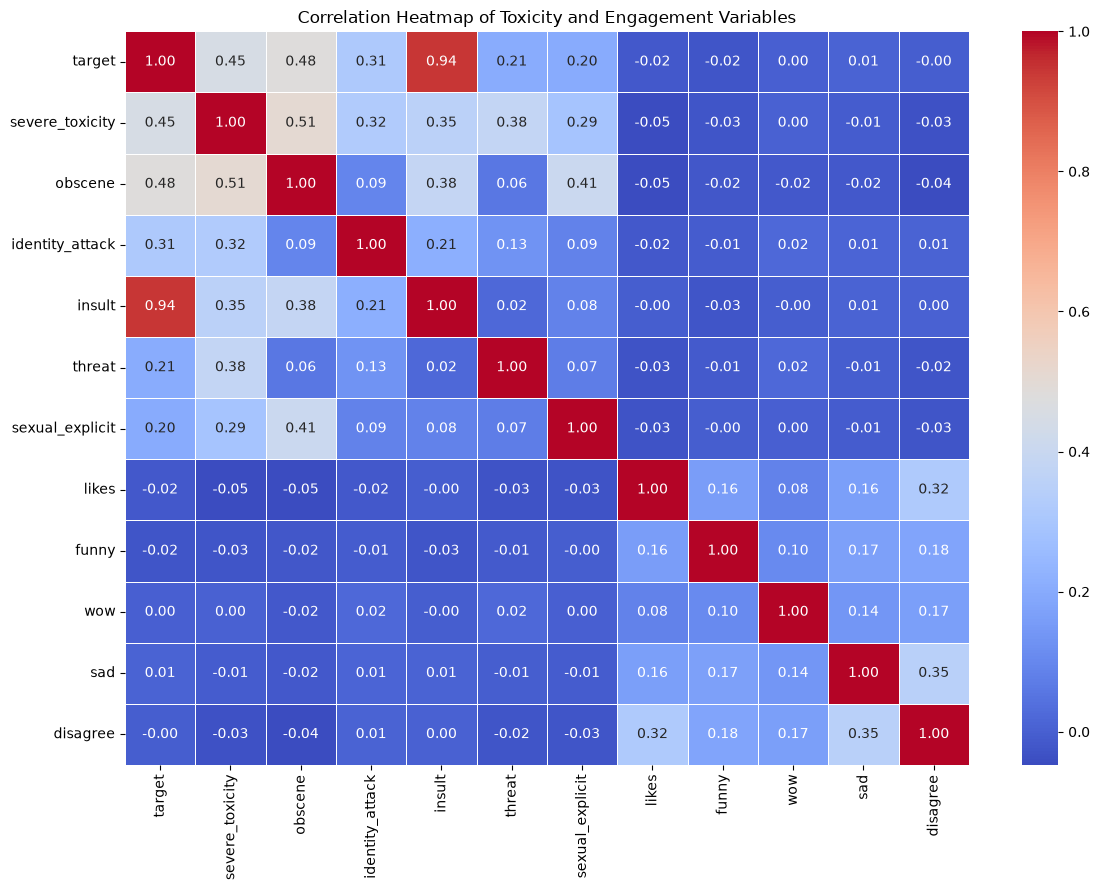

In [26]:
# Select meaningful numerical columns

correlation_columns = [
    "target",
    "severe_toxicity",
    "obscene",
    "identity_attack",
    "insult",
    "threat",
    "sexual_explicit",
    "likes",
    "funny",
    "wow",
    "sad",
    "disagree"
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Toxicity and Engagement Variables")
plt.tight_layout()
plt.show()

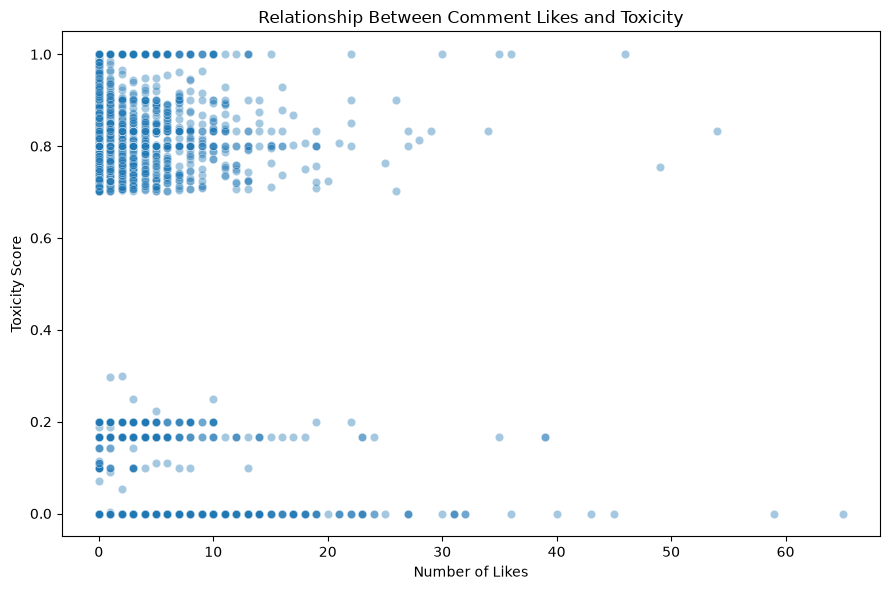

In [27]:
# Relationship between likes and toxicity

sample_data = df.sample(
    n=min(5000, len(df)),
    random_state=42
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=sample_data,
    x="likes",
    y="target",
    alpha=0.4
)

plt.title("Relationship Between Comment Likes and Toxicity")
plt.xlabel("Number of Likes")
plt.ylabel("Toxicity Score")

plt.tight_layout()
plt.show()

In [28]:
# Calculate correlation

likes_correlation = df["likes"].corr(df["target"])

print("Correlation between Likes and Toxicity:", likes_correlation)

Correlation between Likes and Toxicity: -0.015398528280242


### Bivariate Analysis Interpretation

The correlation heatmap shows the linear relationships between toxicity categories and engagement variables.

The scatter plot explores the relationship between comment likes and toxicity scores. Correlation indicates association, not causation.

## 7. Answering Research Questions

In this section, we answer our research questions using data visualizations and statistical analysis.

### Question 1: What is the distribution of overall toxicity scores?

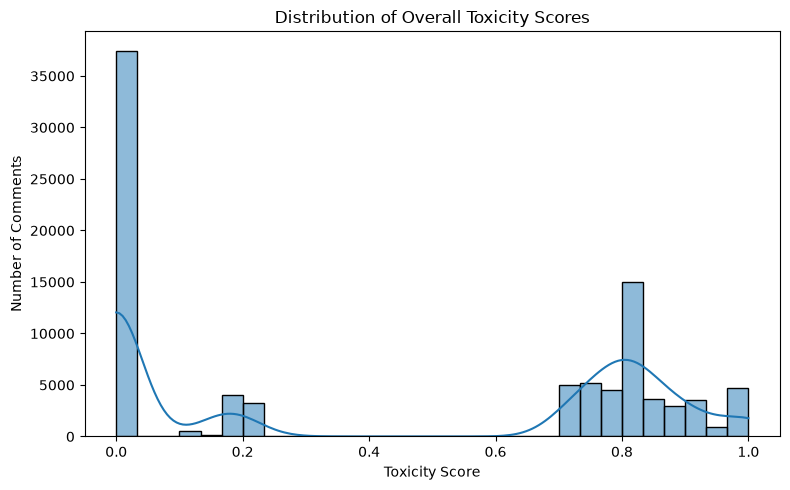

Average Toxicity: 0.43025410113493645
Median Toxicity: 0.500119812


In [29]:
plt.figure(figsize=(8, 5))

sns.histplot(df["target"], bins=30, kde=True)

plt.title("Distribution of Overall Toxicity Scores")
plt.xlabel("Toxicity Score")
plt.ylabel("Number of Comments")

plt.tight_layout()
plt.show()

print("Average Toxicity:", df["target"].mean())
print("Median Toxicity:", df["target"].median())

The histogram shows the distribution of overall toxicity scores. The mean and median help describe the typical toxicity level in the dataset.

### Question 2: Which toxicity category has the highest average score?

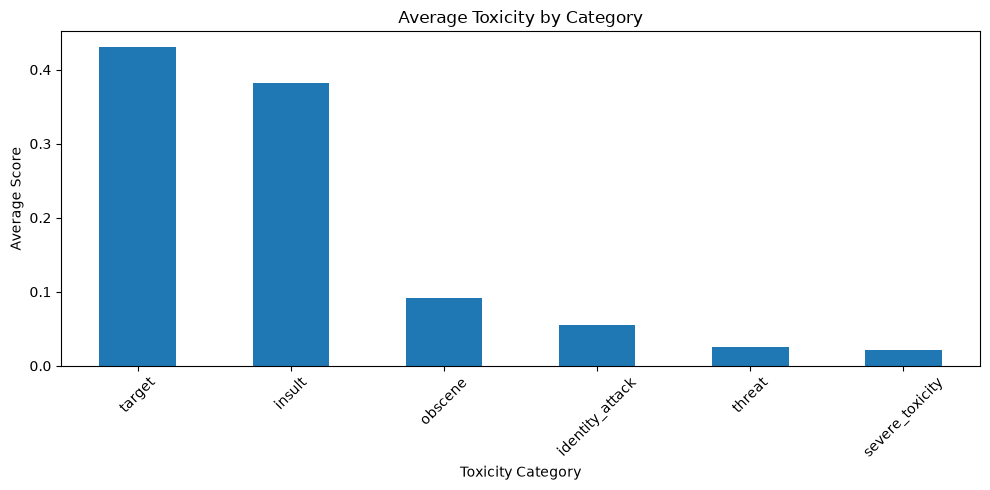

Highest Average: target
Average Score: 0.43025410113493645


In [30]:
toxicity_columns = [
    "target",
    "severe_toxicity",
    "obscene",
    "identity_attack",
    "insult",
    "threat"
]

category_means = df[toxicity_columns].mean().sort_values(
    ascending=False
)

category_means.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Toxicity by Category")
plt.xlabel("Toxicity Category")
plt.ylabel("Average Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Highest Average:", category_means.index[0])
print("Average Score:", category_means.iloc[0])

The bar chart compares average scores across toxicity categories. The category with the highest average score represents the highest average annotation score in this dataset.

### Question 3: Which identity category has the highest average toxicity?

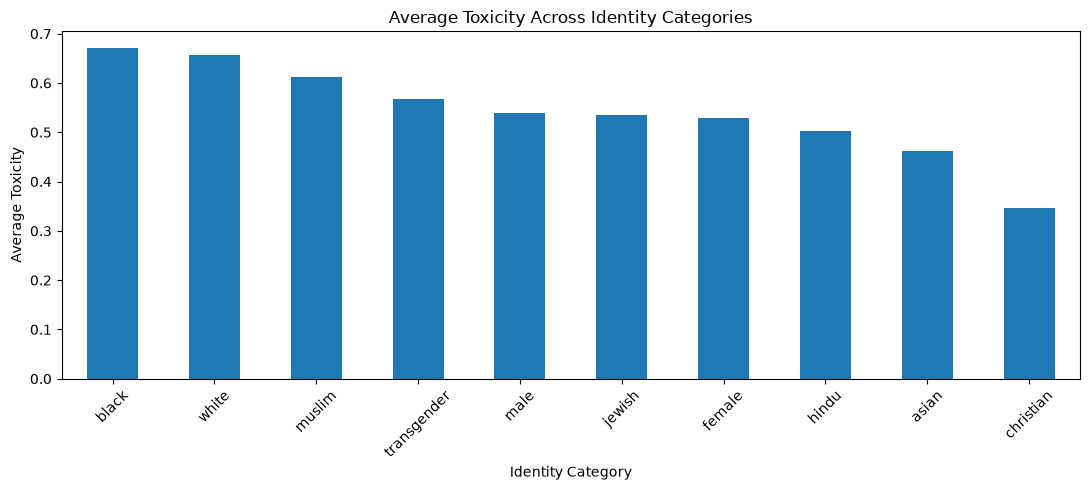

black          0.671153
white          0.656605
muslim         0.611415
transgender    0.566951
male           0.538628
jewish         0.535526
female         0.528640
hindu          0.503373
asian          0.461059
christian      0.346854
dtype: float64


In [31]:
identity_results = {}

for column in identity_columns:
    selected = df[df[column] > 0]
    identity_results[column] = selected["target"].mean()

identity_results = pd.Series(identity_results).dropna().sort_values(
    ascending=False
)

identity_results.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Average Toxicity Across Identity Categories")
plt.xlabel("Identity Category")
plt.ylabel("Average Toxicity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(identity_results)

The chart compares average toxicity scores across selected identity-related annotations. Differences indicate patterns for further investigation, not proof of AI bias.

### Question 4: Is identity attack related to overall toxicity?

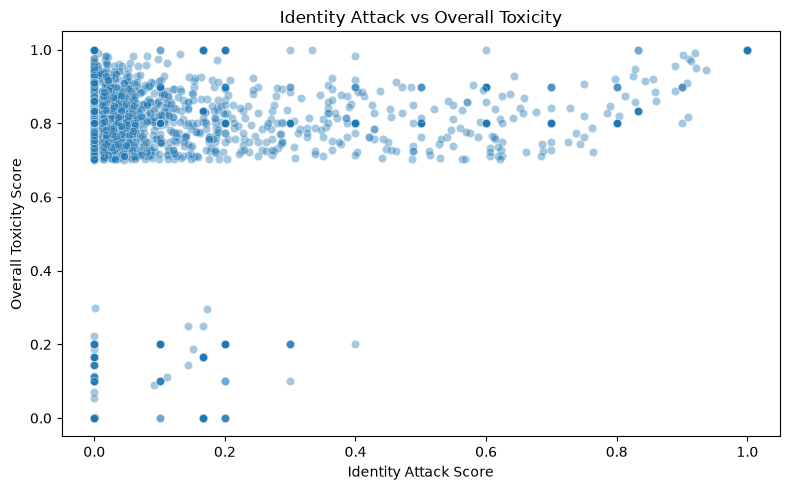

Correlation: 0.3141192898916314


In [33]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df.sample(n=min(5000, len(df)), random_state=42),
    x="identity_attack",
    y="target",
    alpha=0.4
)

plt.title("Identity Attack vs Overall Toxicity")
plt.xlabel("Identity Attack Score")
plt.ylabel("Overall Toxicity Score")

plt.tight_layout()
plt.show()

print(
    "Correlation:",
    df["identity_attack"].corr(df["target"])
)

The scatter plot and correlation coefficient show the relationship between identity attack scores and overall toxicity scores. Correlation does not establish causation.

### Question 5: Do approved and rejected comments have different toxicity scores?

rating
approved    0.367265
rejected    0.725467
Name: target, dtype: float64


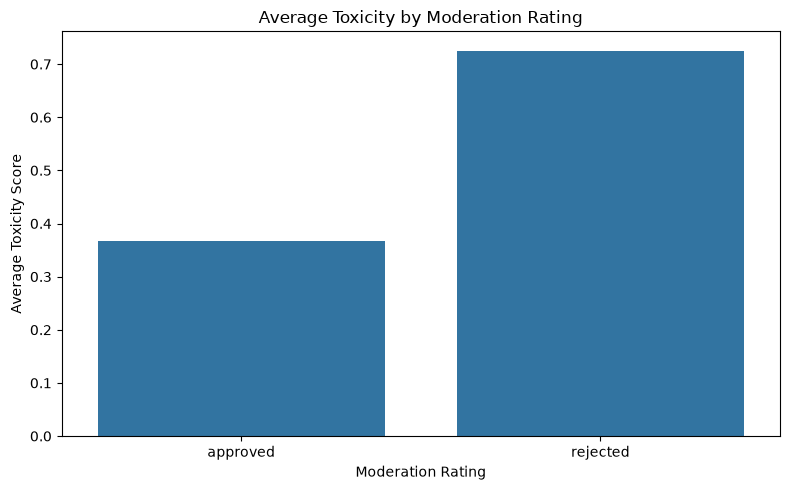

In [34]:
# Compare toxicity across moderation ratings

rating_toxicity = df.groupby("rating")["target"].mean()

print(rating_toxicity)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=rating_toxicity.index,
    y=rating_toxicity.values
)

plt.title("Average Toxicity by Moderation Rating")
plt.xlabel("Moderation Rating")
plt.ylabel("Average Toxicity Score")

plt.tight_layout()
plt.show()

Approved comments have an average toxicity score of approximately 0.367, while rejected comments have an average score of approximately 0.725. Rejected comments therefore show higher average toxicity in this dataset.

### Question 6: Is there a relationship between comment likes and toxicity scores?

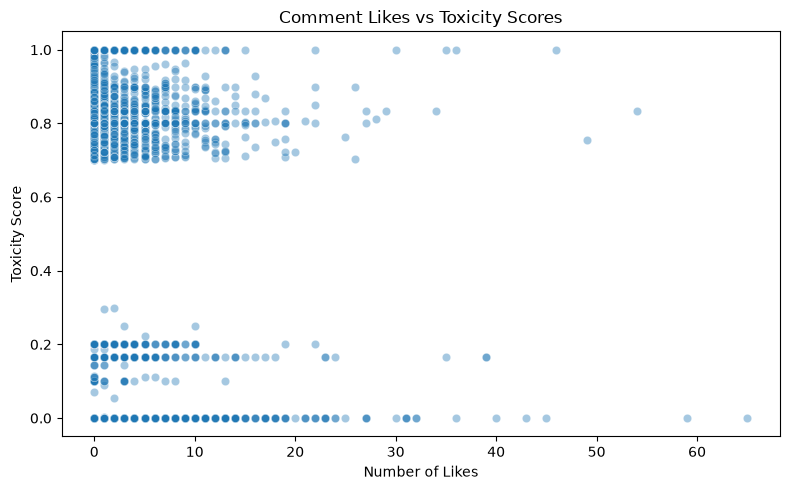

Correlation: -0.015398528280242


In [35]:
# Relationship between likes and toxicity

sample_data = df.sample(
    n=min(5000, len(df)),
    random_state=42
)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=sample_data,
    x="likes",
    y="target",
    alpha=0.4
)

plt.title("Comment Likes vs Toxicity Scores")
plt.xlabel("Number of Likes")
plt.ylabel("Toxicity Score")

plt.tight_layout()
plt.show()

print("Correlation:", df["likes"].corr(df["target"]))

The correlation between likes and toxicity is approximately -0.015, indicating a very weak negative linear relationship. Likes are not strongly associated with toxicity scores in this dataset.

### Question 7: Do identity-related comments have different toxicity scores?

identity_group
Identity Annotated                 0.532338
No Selected Identity Annotation    0.415438
Name: target, dtype: float64


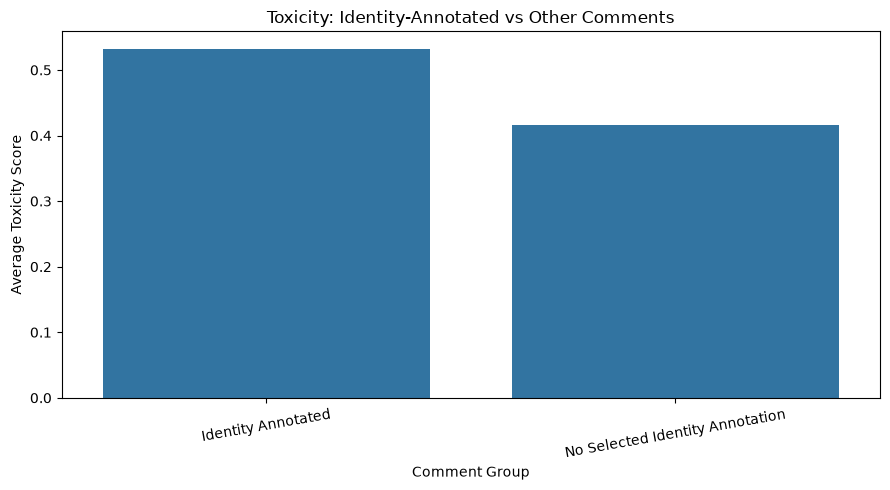

In [36]:
# Identify comments with selected identity annotations

identity_present = (df[identity_columns] > 0).any(axis=1)

df["identity_group"] = np.where(
    identity_present,
    "Identity Annotated",
    "No Selected Identity Annotation"
)

# Compare average toxicity

group_toxicity = df.groupby("identity_group")["target"].mean()

print(group_toxicity)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=group_toxicity.index,
    y=group_toxicity.values
)

plt.title("Toxicity: Identity-Annotated vs Other Comments")
plt.xlabel("Comment Group")
plt.ylabel("Average Toxicity Score")

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

Comments with selected identity-related annotations have an average toxicity score of approximately 0.532, compared with 0.415 for comments without these annotations. This difference suggests a pattern worth investigating, but does not prove AI bias.

### Question 8: How are comments distributed between approved and rejected categories?

rating
approved    74917
rejected    15985
Name: count, dtype: int64


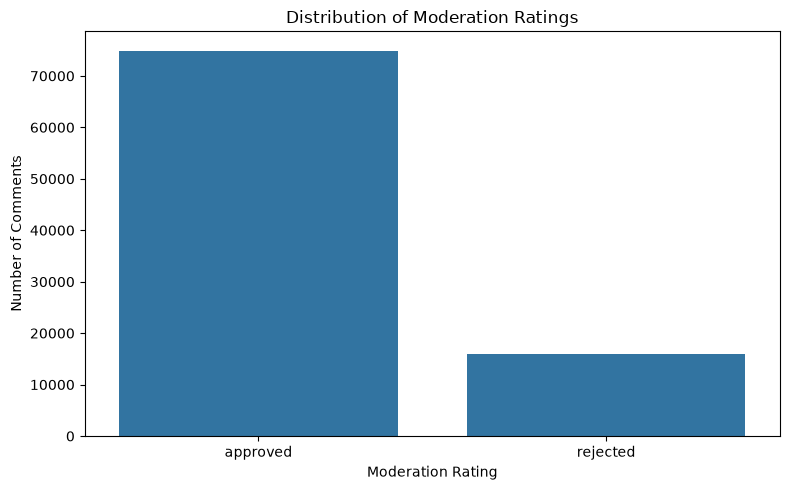

In [37]:
# Count moderation categories

rating_counts = df["rating"].value_counts()

print(rating_counts)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values
)

plt.title("Distribution of Moderation Ratings")
plt.xlabel("Moderation Rating")
plt.ylabel("Number of Comments")

plt.tight_layout()
plt.show()

The dataset contains 74,917 approved comments and 15,985 rejected comments. Approved comments represent the larger portion of the dataset.

## 8. Conclusion and Recommendations

This project explored potential patterns in AI toxicity classification using the Jigsaw dataset.

### Key Findings

1. The average overall toxicity score is approximately 0.430.

2. Rejected comments have a higher average toxicity score (0.725) than approved comments (0.367).

3. Comments with selected identity-related annotations have a higher average toxicity score (0.532) than comments without those annotations (0.415).

### Recommendation

AI developers should evaluate toxicity classification models across different identity-related categories, review false positives and false negatives, and use diverse human evaluations to reduce potential bias.

### Missing Values Handling Decision

The identity-related annotation columns contain 69,215 missing values each. These values will not automatically be replaced with zero because missing annotations do not necessarily mean that an identity was not mentioned.

The parent_id column contains 41,072 missing values, which may represent comments without a parent comment.

These missing values will be retained to avoid losing potentially useful information.

In [38]:
# Final dataset verification

print("Final Dataset Shape:", df.shape)

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nDate Column Data Type:", df["created_date"].dtype)

print("\nRemaining Missing Values:", df.isnull().sum().sum())


Final Dataset Shape: (90902, 46)

Duplicate Rows: 0

Date Column Data Type: datetime64[us, UTC]

Remaining Missing Values: 1702232
